# Step 5. Final Segment Profiling & Strategy - k=5

이 노트북은 Step 4에서 최종 선택한 `core_7_KMeans_k5` label을 기준으로 segment별 행동 특성, 이탈률, high-risk signal, 고객 속성 분포를 해석한다.

Clustering은 Step 4에서 완료되었으므로 이 노트북에서는 clustering을 다시 수행하지 않는다.  
Step 4의 최종 산출물인 `13_final_customer_segments_core7_kmeans_k5.csv`가 있으면 그 파일을 우선 사용한다.


In [1]:
from pathlib import Path
import sys
import json
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px


def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for path in [current] + list(current.parents):
        if (path / "data").exists() and (path / "src").exists():
            return path
    return current

ROOT = find_project_root()
sys.path.insert(0, str(ROOT))

from src.common import read_csv_safely, save_csv, save_json, configure_korean_font, get_plotly_layout

# ------------------------------------------------------------
# Reproducibility guard
# ------------------------------------------------------------
# Step 5 자체는 clustering을 다시 수행하지 않으므로 무작위성이 거의 없다.
# 그래도 이후 샘플링/시각화 확장 가능성을 위해 seed를 고정한다.
RANDOM_STATE = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

configure_korean_font()
print("Project root:", ROOT)
print("Random state:", RANDOM_STATE)


[font] Matplotlib Korean font: Malgun Gothic
Project root: C:\Users\user\Desktop\BankChurners-Customer-Segmentation
Random state: 42


## 1. Final model configuration

Step 5는 최종 선택 모델을 다시 고르지 않는다. `core_7_KMeans_k5`만 사용한다.


In [2]:
FINAL_MODEL_KEY = "core_7_KMeans_k5"
FINAL_FEATURE_SET = "core_7"
FINAL_N_CLUSTERS = 5

SEGMENT_NAME_MAP_K5 = {
    0: "상품 관계 중심 저위험 안정군",
    1: "신용 활용 중심 저위험 금융활용군",
    2: "고활동·저관계 잠재 전환군",
    3: "거래 감소·저활동·접촉 부담형 초고위험 이탈군",
    4: "저활동·비감소형 초저위험 안정군",
}

SEGMENT_STRATEGY_MAP_K5 = {
    0: "기존 상품 관계 유지, 과도한 접촉 지양, 맞춤형 부가 혜택 제안",
    1: "신용 이용 패턴 기반 한도·금리·상환 안내, 우량 금융활용 고객 관리",
    2: "주거래화 유도, 관계 상품 확대, 활동 기반 교차판매 캠페인",
    3: "최우선 이탈 방어, 거래 감소 원인 확인, 접촉 피로도 완화, 관계 회복형 혜택 제공",
    4: "저비용 유지 관리, 불필요한 프로모션 최소화, 안정 고객 모니터링",
}

SEGMENT_DESCRIPTION_MAP_K5 = {
    0: "상품 관계가 높고 이탈률이 낮은 안정 고객군",
    1: "신용 활용도가 높지만 이탈률은 낮은 금융활용 고객군",
    2: "활동성은 높지만 상품 관계가 약한 잠재 전환 고객군",
    3: "거래 횟수·금액 감소와 접촉 부담이 동시에 나타나는 초고위험 이탈군",
    4: "활동성은 낮지만 거래 감소 신호가 거의 없는 초저위험 안정군",
}

print("Final model:", FINAL_MODEL_KEY)


Final model: core_7_KMeans_k5


## 2. Step 4 final segment table 로드

우선 Step 4 수정본이 생성하는 `13_final_customer_segments_core7_kmeans_k5.csv`를 읽는다.  
이 파일이 없으면 기존 Step 4 산출물(`10_selected_cluster_labels.csv`, `11_df_cluster_input_used.csv`, `12_df_profile_table_used.csv`)로 fallback하되, 선택 모델이 k=5인지 검증한다.


In [3]:
input_dir = ROOT / "data" / "analysis" / "clustering_results"
output_dir = ROOT / "data" / "analysis" / "segment_profiling" / FINAL_MODEL_KEY
output_dir.mkdir(parents=True, exist_ok=True)

selected_model_path = input_dir / "09_selected_model.json"
final_segment_path = input_dir / "13_final_customer_segments_core7_kmeans_k5.csv"

selected_model = {}
if selected_model_path.exists():
    with open(selected_model_path, "r", encoding="utf-8") as f:
        selected_model = json.load(f)

selected_key_from_step4 = selected_model.get("selected_key")
if selected_key_from_step4 and selected_key_from_step4 != FINAL_MODEL_KEY:
    print(f"[WARNING] Step 4 selected_key is {selected_key_from_step4}, but Step 5 is fixed to {FINAL_MODEL_KEY}.")
    print("          Step 4 수정본을 다시 실행하여 final k=5 산출물을 생성했는지 확인하세요.")

# feature columns 로드. Step 4 metadata가 없을 때를 대비한 fallback.
DEFAULT_CORE7_FEATURE_COLS = [
    "Activity_Score",
    "Count_Decline_Risk_Score",
    "Amount_Decline_Risk_Score",
    "Inactivity_Score",
    "Product_Relationship_Score",
    "Contact_Burden_Score",
    "Credit_Utilization_Score",
]
feature_cols = selected_model.get("feature_columns", DEFAULT_CORE7_FEATURE_COLS)

if final_segment_path.exists():
    df_seg = read_csv_safely(final_segment_path)
    print("Loaded final segment table:", final_segment_path.relative_to(ROOT))
else:
    required_files = [
        input_dir / "11_df_cluster_input_used.csv",
        input_dir / "12_df_profile_table_used.csv",
        input_dir / "10_selected_cluster_labels.csv",
    ]
    missing_files = [p for p in required_files if not p.exists()]
    if missing_files:
        raise FileNotFoundError(
            "Step 4 결과 파일이 부족합니다. 먼저 04_clustering_model_selection_k5_final.ipynb를 실행하세요.\n"
            + "\n".join(str(p.relative_to(ROOT)) for p in missing_files)
        )
    if selected_key_from_step4 != FINAL_MODEL_KEY:
        raise ValueError(
            f"현재 Step 4 selected_key가 {selected_key_from_step4}입니다. "
            f"Step 5는 {FINAL_MODEL_KEY} 전용입니다. Step 4 수정본을 다시 실행하세요."
        )

    df_cluster = read_csv_safely(input_dir / "11_df_cluster_input_used.csv")
    df_profile = read_csv_safely(input_dir / "12_df_profile_table_used.csv")
    selected_labels = read_csv_safely(input_dir / "10_selected_cluster_labels.csv")

    df_seg = df_profile.copy()
    df_seg["Row_ID"] = df_cluster["Row_ID"].values if "Row_ID" in df_cluster.columns else np.arange(len(df_seg))
    df_seg["Cluster"] = selected_labels["Cluster"].values
    if "Cluster_Label" in selected_labels.columns:
        df_seg["Cluster_Label"] = selected_labels["Cluster_Label"].values
    if "Segment_Name" in selected_labels.columns:
        df_seg["Segment_Name"] = selected_labels["Segment_Name"].values

    for col in feature_cols:
        if col in df_cluster.columns and col not in df_seg.columns:
            df_seg[col] = df_cluster[col].values

# basic cleanup
if "Cluster" not in df_seg.columns:
    raise KeyError("df_seg에 Cluster 컬럼이 없습니다. Step 4 final segment table을 확인하세요.")

df_seg["Cluster"] = df_seg["Cluster"].astype(int)
df_seg["Cluster_Label"] = df_seg.get("Cluster_Label", df_seg["Cluster"].map(lambda x: f"C{int(x)}"))
df_seg["Segment_Name"] = df_seg["Cluster"].map(SEGMENT_NAME_MAP_K5).fillna(df_seg.get("Segment_Name", df_seg["Cluster_Label"]))
df_seg["Segment_Description"] = df_seg["Cluster"].map(SEGMENT_DESCRIPTION_MAP_K5)
df_seg["Recommended_Strategy"] = df_seg["Cluster"].map(SEGMENT_STRATEGY_MAP_K5)

# feature columns present in current table
feature_cols = [col for col in feature_cols if col in df_seg.columns]
if not feature_cols:
    raise ValueError("core_7 feature columns를 찾지 못했습니다. Step 4 산출물에 feature columns가 포함되어 있는지 확인하세요.")

if "High_Risk_Signal_Count" not in df_seg.columns:
    risk_flag_candidates = [
        "Strong_Decline_Flag", "Decline_Low_Activity_Flag", "High_Inactive_Flag",
        "High_Contact_Flag", "Low_Bank_Product_Count_Flag", "Zero_Utilization_Flag",
    ]
    risk_flag_candidates = [col for col in risk_flag_candidates if col in df_seg.columns]
    if risk_flag_candidates:
        df_seg["High_Risk_Signal_Count"] = df_seg[risk_flag_candidates].sum(axis=1)
    else:
        df_seg["High_Risk_Signal_Count"] = np.nan

if "Attrition_Flag" not in df_seg.columns:
    raise KeyError("Attrition_Flag 컬럼이 없습니다. 이탈률 계산을 위해 Step 4/Step 3 산출물을 확인하세요.")

print("df_seg:", df_seg.shape)
print("Feature columns:", feature_cols)
display(df_seg[["Cluster", "Cluster_Label", "Segment_Name"]].drop_duplicates().sort_values("Cluster"))


Loaded final segment table: data\analysis\clustering_results\13_final_customer_segments_core7_kmeans_k5.csv
df_seg: (10127, 31)
Feature columns: ['Activity_Score', 'Count_Decline_Risk_Score', 'Amount_Decline_Risk_Score', 'Inactivity_Score', 'Product_Relationship_Score', 'Contact_Burden_Score', 'Credit_Utilization_Score']


,Cluster,Cluster_Label,Segment_Name
10,0,C0,상품 관계 중심 저위험 안정군
35,1,C1,신용 활용 중심 저위험 금융활용군
209,2,C2,고활동·저관계 잠재 전환군
21,3,C3,거래 감소·저활동·접촉 부담형 초고위험 이탈군
0,4,C4,저활동·비감소형 초저위험 안정군


## 3. Segment profiling summary

표준화된 행동축 평균, 원래 단위의 주요 변수 평균, 이탈률, high-risk signal 평균을 모두 저장한다.


In [4]:
group_cols = ["Cluster", "Cluster_Label", "Segment_Name"]

# 고객 수, 이탈률, signal count
profile_summary = df_seg.groupby(group_cols, dropna=False).agg(
    n_customers=("Attrition_Flag", "size"),
    attrition_rate=("Attrition_Flag", "mean"),
    mean_high_risk_signal_count=("High_Risk_Signal_Count", "mean"),
).reset_index()

profile_summary["cluster_ratio"] = profile_summary["n_customers"] / len(df_seg)
profile_summary["cluster_ratio_percent"] = profile_summary["cluster_ratio"] * 100
profile_summary["attrition_rate_percent"] = profile_summary["attrition_rate"] * 100

# 위험 수준은 실제 이탈률 기준으로 부여
# C3처럼 전체 평균보다 크게 높은 군집을 High로 표시한다.
overall_attrition = df_seg["Attrition_Flag"].mean()

def assign_risk_level(rate: float) -> str:
    if rate >= 0.30:
        return "High"
    if rate >= overall_attrition:
        return "Medium"
    return "Low"

profile_summary["risk_level"] = profile_summary["attrition_rate"].apply(assign_risk_level)
profile_summary["segment_description"] = profile_summary["Cluster"].map(SEGMENT_DESCRIPTION_MAP_K5)
profile_summary["recommended_strategy"] = profile_summary["Cluster"].map(SEGMENT_STRATEGY_MAP_K5)

save_csv(profile_summary, output_dir / "00_segment_summary_core7_kmeans_k5.csv")
display(profile_summary.sort_values("Cluster"))


,Cluster,Cluster_Label,Segment_Name,n_customers,attrition_rate,mean_high_risk_signal_count,cluster_ratio,cluster_ratio_percent,attrition_rate_percent,risk_level,segment_description,recommended_strategy
0,0,C0,상품 관계 중심 저위험 안정군,2373,0.086389,0.600084,0.234324,23.432408,8.638854,Low,상품 관계가 높고 이탈률이 낮은 안정 고객군,"기존 상품 관계 유지, 과도한 접촉 지양, 맞춤형 부가 혜택 제안"
1,1,C1,신용 활용 중심 저위험 금융활용군,2258,0.081931,0.369353,0.222968,22.296830,8.193091,Low,신용 활용도가 높지만 이탈률은 낮은 금융활용 고객군,"신용 이용 패턴 기반 한도·금리·상환 안내, 우량 금융활용 고객 관리"
2,2,C2,고활동·저관계 잠재 전환군,2324,0.081325,1.017212,0.229486,22.948553,8.132530,Low,활동성은 높지만 상품 관계가 약한 잠재 전환 고객군,"주거래화 유도, 관계 상품 확대, 활동 기반 교차판매 캠페인"
3,3,C3,거래 감소·저활동·접촉 부담형 초고위험 이탈군,2174,0.459522,1.673873,0.214674,21.467364,45.952162,High,거래 횟수·금액 감소와 접촉 부담이 동시에 나타나는 초고위험 이탈군,"최우선 이탈 방어, 거래 감소 원인 확인, 접촉 피로도 완화, 관계 회복형 혜택 제공"
4,4,C4,저활동·비감소형 초저위험 안정군,998,0.049098,0.441884,0.098548,9.854843,4.909820,Low,활동성은 낮지만 거래 감소 신호가 거의 없는 초저위험 안정군,"저비용 유지 관리, 불필요한 프로모션 최소화, 안정 고객 모니터링"


In [5]:
# 표준화 행동축 평균: heatmap 해석용
segment_profile_standardized = df_seg.groupby(group_cols, dropna=False)[feature_cols].mean().reset_index()
save_csv(segment_profile_standardized, output_dir / "01_segment_profile_standardized.csv")

# 원래 단위 profile: 보고서에서 직관적으로 설명할 때 사용
raw_profile_cols = [
    "Total_Trans_Ct",
    "Total_Trans_Amt",
    "Total_Ct_Chng_Q4_Q1",
    "Total_Amt_Chng_Q4_Q1",
    "Months_Inactive_12_mon",
    "Contacts_Count_12_mon",
    "Total_Relationship_Count",
    "Months_on_book",
    "Avg_Utilization_Ratio",
]
raw_profile_cols = [col for col in raw_profile_cols if col in df_seg.columns]

if raw_profile_cols:
    segment_profile_raw = df_seg.groupby(group_cols, dropna=False)[raw_profile_cols].agg(["mean", "median"]).reset_index()
    # flatten multi-index columns
    segment_profile_raw.columns = [
        "_".join([str(x) for x in col if x]) if isinstance(col, tuple) else col
        for col in segment_profile_raw.columns
    ]
    save_csv(segment_profile_raw, output_dir / "02_segment_profile_raw_mean_median.csv")
    display(segment_profile_raw.sort_values("Cluster"))
else:
    segment_profile_raw = pd.DataFrame()
    print("원래 단위 profile에 사용할 raw columns가 없습니다.")


,Cluster,Cluster_Label,Segment_Name,Total_Trans_Ct_mean,Total_Trans_Ct_median,Total_Trans_Amt_mean,Total_Trans_Amt_median,Total_Ct_Chng_Q4_Q1_mean,Total_Ct_Chng_Q4_Q1_median,Total_Amt_Chng_Q4_Q1_mean,Total_Amt_Chng_Q4_Q1_median,Months_Inactive_12_mon_mean,Months_Inactive_12_mon_median,Contacts_Count_12_mon_mean,Contacts_Count_12_mon_median,Total_Relationship_Count_mean,Total_Relationship_Count_median,Avg_Utilization_Ratio_mean,Avg_Utilization_Ratio_median
0,0,C0,상품 관계 중심 저위험 안정군,66.759798,69.0,3940.338390,3950.0,0.730864,0.722,0.747126,0.7440,2.241045,2.0,2.245681,2.0,5.090603,5.0,0.105625,0.065
1,1,C1,신용 활용 중심 저위험 금융활용군,66.181577,70.0,3769.279008,4182.0,0.721840,0.717,0.735656,0.7285,2.391054,2.0,2.328609,2.0,4.260850,4.0,0.667391,0.665
2,2,C2,고활동·저관계 잠재 전환군,89.045611,86.0,8400.538296,7524.0,0.734942,0.730,0.757929,0.7490,2.244836,2.0,2.088640,2.0,2.060671,2.0,0.185321,0.110
3,3,C3,거래 감소·저활동·접촉 부담형 초고위험 이탈군,43.546918,41.0,2171.905704,1989.5,0.500363,0.500,0.626677,0.6240,2.570377,3.0,3.155474,3.0,3.622815,3.0,0.146680,0.073
4,4,C4,저활동·비감소형 초저위험 안정군,47.446894,47.0,2499.151303,2248.0,1.054734,1.000,1.140338,1.0715,2.191383,2.0,2.569138,3.0,4.252505,4.0,0.277214,0.214


## 4. Cluster profile heatmap

이 heatmap의 값은 원점수가 아니라 `Standardized Mean`이다. 0은 전체 평균 수준, +1은 전체 평균보다 1 표준편차 높음, -1은 1 표준편차 낮음을 의미한다.


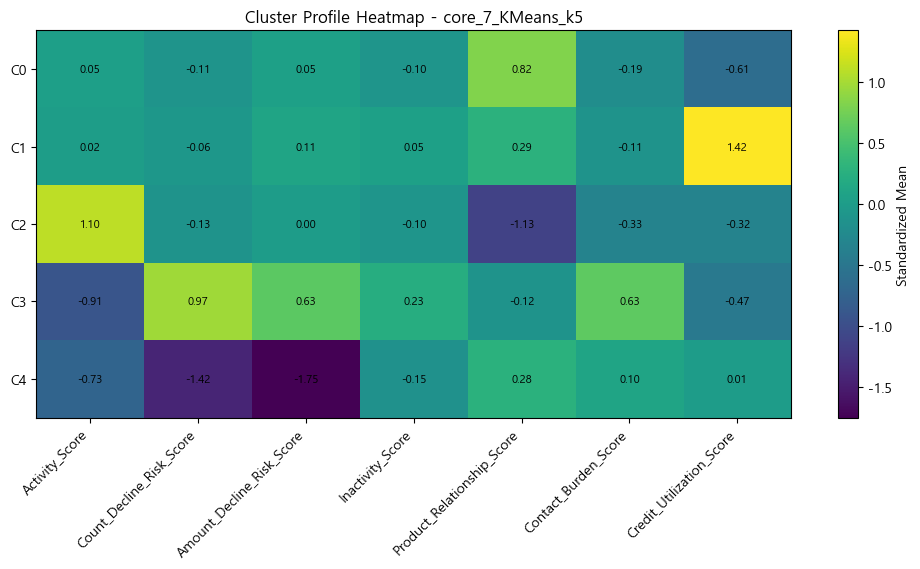

In [6]:
axis_profile = segment_profile_standardized.copy()
heatmap_data = axis_profile[feature_cols].values
row_labels = axis_profile["Cluster_Label"].tolist()

plt.figure(figsize=(max(10, len(feature_cols) * 1.4), 5.8))
plt.imshow(heatmap_data, aspect="auto")
plt.colorbar(label="Standardized Mean")
plt.xticks(range(len(feature_cols)), feature_cols, rotation=45, ha="right")
plt.yticks(range(len(row_labels)), row_labels)
plt.title(f"Cluster Profile Heatmap - {FINAL_MODEL_KEY}")

for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        plt.text(j, i, f"{heatmap_data[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.savefig(output_dir / "03_cluster_profile_heatmap_k5.png", dpi=300)
plt.show()


## 5. Segment별 이탈률


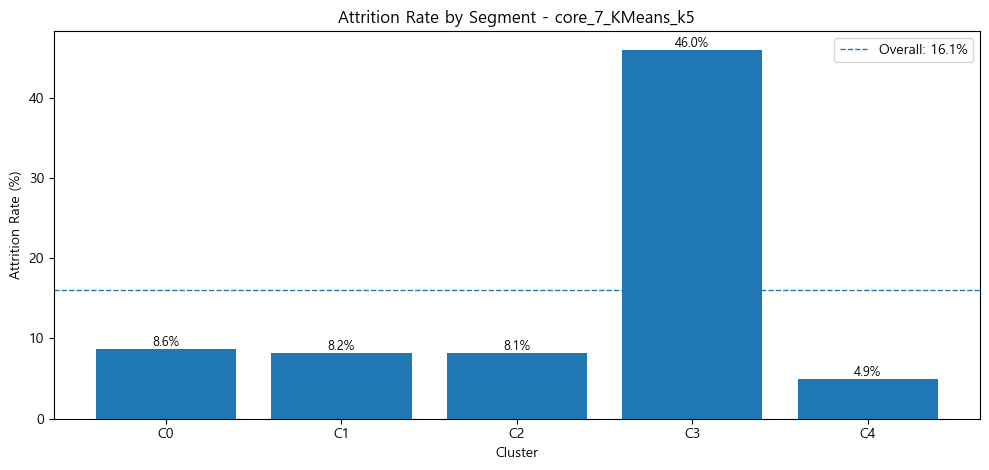

In [7]:
plot_df = profile_summary.sort_values("Cluster").copy()
overall_attrition_percent = overall_attrition * 100

plt.figure(figsize=(10, 4.8))
bars = plt.bar(plot_df["Cluster_Label"], plot_df["attrition_rate_percent"])
plt.axhline(
    overall_attrition_percent,
    linestyle="--",
    linewidth=1,
    label=f"Overall: {overall_attrition_percent:.1f}%"
)
plt.xlabel("Cluster")
plt.ylabel("Attrition Rate (%)")
plt.title(f"Attrition Rate by Segment - {FINAL_MODEL_KEY}")
plt.legend()

for bar, val in zip(bars, plot_df["attrition_rate_percent"]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{val:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.savefig(output_dir / "04_attrition_rate_by_segment_k5.png", dpi=300)
plt.show()


## 6. Segment size vs attrition bubble chart


In [8]:
bubble_df = profile_summary.copy()

# bubble size로 쓸 수 있는 raw metric이 있으면 연결
if "Total_Trans_Amt" in df_seg.columns:
    amount_by_cluster = df_seg.groupby("Cluster")["Total_Trans_Amt"].mean().rename("mean_total_trans_amt").reset_index()
    bubble_df = bubble_df.merge(amount_by_cluster, on="Cluster", how="left")
    size_col = "mean_total_trans_amt"
else:
    size_col = "n_customers"

fig = px.scatter(
    bubble_df,
    x="cluster_ratio_percent",
    y="attrition_rate_percent",
    size=size_col,
    color="Cluster_Label",
    hover_data=[
        "Segment_Name",
        "n_customers",
        "cluster_ratio_percent",
        "attrition_rate_percent",
        "mean_high_risk_signal_count",
        "risk_level",
    ],
    title=f"Segment Size vs Attrition Rate - {FINAL_MODEL_KEY}",
    labels={
        "cluster_ratio_percent": "Customer Ratio (%)",
        "attrition_rate_percent": "Attrition Rate (%)",
    },
    size_max=60,
)
fig.add_hline(y=overall_attrition_percent, line_dash="dash", annotation_text="Overall Attrition Rate")
fig.update_layout(**get_plotly_layout())
fig.show()
fig.write_html(output_dir / "05_segment_size_vs_attrition_bubble_k5.html")


## 7. High-risk signal summary

`High_Risk_Signal_Count`는 모델 rank가 아니라, 고객별 위험 신호 개수의 군집 평균이다.  
아래 표에서는 각 signal flag가 해당 segment에서 얼마나 자주 나타나는지도 함께 계산한다.


,Cluster,Cluster_Label,Segment_Name,High_Risk_Signal_Count,Strong_Decline_Flag,Decline_Low_Activity_Flag,High_Inactive_Flag,High_Contact_Flag,Low_Bank_Product_Count_Flag,Zero_Utilization_Flag,Strong_Decline_Flag_Rate_Percent,Decline_Low_Activity_Flag_Rate_Percent,High_Inactive_Flag_Rate_Percent,High_Contact_Flag_Rate_Percent,Low_Bank_Product_Count_Flag_Rate_Percent,Zero_Utilization_Flag_Rate_Percent
0,0,C0,상품 관계 중심 저위험 안정군,0.600,0.018963,0.018542,0.059418,0.118416,0.000421,0.384324,1.896334,1.854193,5.941846,11.841551,0.042141,38.432364
1,1,C1,신용 활용 중심 저위험 금융활용군,0.369,0.036758,0.044287,0.089460,0.120461,0.078388,0.000000,3.675819,4.428698,8.945970,12.046058,7.838795,0.000000
2,2,C2,고활동·저관계 잠재 전환군,1.017,0.006454,0.000861,0.055077,0.037866,0.671256,0.245697,0.645439,0.086059,5.507745,3.786575,67.125645,24.569707
3,3,C3,거래 감소·저활동·접촉 부담형 초고위험 이탈군,1.674,0.305888,0.349126,0.101196,0.362925,0.168813,0.385925,30.588776,34.912603,10.119595,36.292548,16.881325,38.592456
4,4,C4,저활동·비감소형 초저위험 안정군,0.442,0.000000,0.007014,0.046092,0.192385,0.048096,0.148297,0.000000,0.701403,4.609218,19.238477,4.809619,14.829659


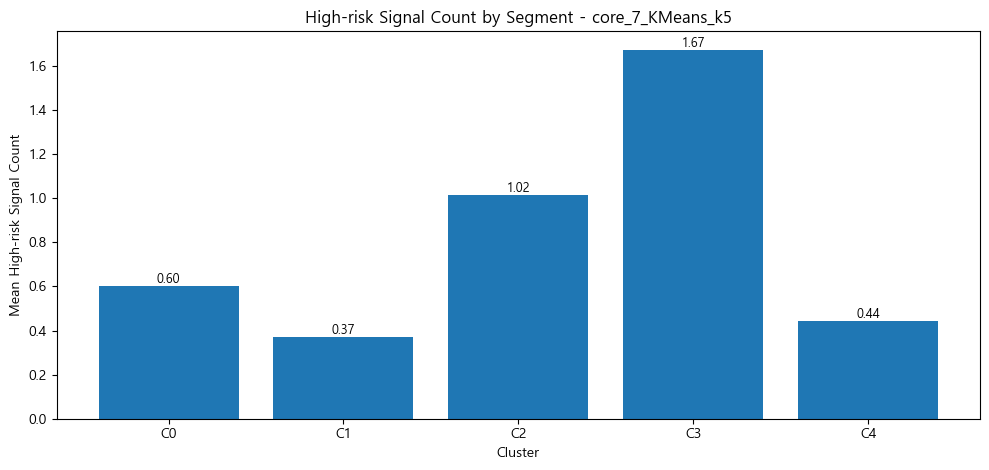

In [9]:
risk_flag_cols = [
    "Strong_Decline_Flag",
    "Decline_Low_Activity_Flag",
    "High_Inactive_Flag",
    "High_Contact_Flag",
    "Low_Bank_Product_Count_Flag",
    "Zero_Utilization_Flag",
]
risk_flag_cols = [col for col in risk_flag_cols if col in df_seg.columns]

risk_summary_cols = ["High_Risk_Signal_Count"] + risk_flag_cols
risk_summary = df_seg.groupby(group_cols, dropna=False)[risk_summary_cols].mean().reset_index()

# flag는 비율로 해석 가능하므로 percent 컬럼 추가
for col in risk_flag_cols:
    risk_summary[f"{col}_Rate_Percent"] = risk_summary[col] * 100

risk_summary["High_Risk_Signal_Count"] = risk_summary["High_Risk_Signal_Count"].round(3)
save_csv(risk_summary, output_dir / "06_high_risk_signal_summary.csv")
display(risk_summary.sort_values("Cluster"))

plt.figure(figsize=(10, 4.8))
plt.bar(risk_summary["Cluster_Label"], risk_summary["High_Risk_Signal_Count"])
plt.xlabel("Cluster")
plt.ylabel("Mean High-risk Signal Count")
plt.title(f"High-risk Signal Count by Segment - {FINAL_MODEL_KEY}")

for x, val in zip(risk_summary["Cluster_Label"], risk_summary["High_Risk_Signal_Count"]):
    plt.text(x, val, f"{val:.2f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(output_dir / "07_high_risk_signal_count_by_segment_k5.png", dpi=300)
plt.show()


In [10]:
# Signal component rates long table: 어떤 위험 신호가 segment별로 많이 나타나는지 확인
if risk_flag_cols:
    signal_component_rates = risk_summary[group_cols + risk_flag_cols].copy()
    signal_component_rates_long = signal_component_rates.melt(
        id_vars=group_cols,
        value_vars=risk_flag_cols,
        var_name="signal_component",
        value_name="rate",
    )
    signal_component_rates_long["rate_percent"] = signal_component_rates_long["rate"] * 100
    save_csv(signal_component_rates_long, output_dir / "08_signal_component_rates_long.csv")
    display(signal_component_rates_long.head(20))
else:
    signal_component_rates_long = pd.DataFrame()
    print("위험 신호 구성 flag 컬럼이 없습니다.")


,Cluster,Cluster_Label,Segment_Name,signal_component,rate,rate_percent
0,0,C0,상품 관계 중심 저위험 안정군,Strong_Decline_Flag,0.018963,1.896334
1,1,C1,신용 활용 중심 저위험 금융활용군,Strong_Decline_Flag,0.036758,3.675819
2,2,C2,고활동·저관계 잠재 전환군,Strong_Decline_Flag,0.006454,0.645439
3,3,C3,거래 감소·저활동·접촉 부담형 초고위험 이탈군,Strong_Decline_Flag,0.305888,30.588776
4,4,C4,저활동·비감소형 초저위험 안정군,Strong_Decline_Flag,0.000000,0.000000
5,0,C0,상품 관계 중심 저위험 안정군,Decline_Low_Activity_Flag,0.018542,1.854193
6,1,C1,신용 활용 중심 저위험 금융활용군,Decline_Low_Activity_Flag,0.044287,4.428698
7,2,C2,고활동·저관계 잠재 전환군,Decline_Low_Activity_Flag,0.000861,0.086059
8,3,C3,거래 감소·저활동·접촉 부담형 초고위험 이탈군,Decline_Low_Activity_Flag,0.349126,34.912603
9,4,C4,저활동·비감소형 초저위험 안정군,Decline_Low_Activity_Flag,0.007014,0.701403


## 8. 범주형 변수 분포

Card, Income, Gender 등은 clustering input에 사용하지 않았으므로 segment profiling에서 사후적으로 분포를 확인한다.


In [11]:
categorical_cols = [
    "Card_Label",
    "Income_Label",
    "Gender_Label",
    "Education_Label",
    "Marital_Label",
    "Attrition_Label",
]
categorical_cols = [col for col in categorical_cols if col in df_seg.columns]

cat_rows = []
for col in categorical_cols:
    ct = pd.crosstab(
        [df_seg["Cluster"], df_seg["Cluster_Label"], df_seg["Segment_Name"]],
        df_seg[col],
        normalize="index"
    )
    long = ct.reset_index().melt(
        id_vars=group_cols,
        var_name="category",
        value_name="ratio"
    )
    long["variable"] = col
    cat_rows.append(long)

if cat_rows:
    categorical_distribution = pd.concat(cat_rows, ignore_index=True)
    categorical_distribution = categorical_distribution[group_cols + ["variable", "category", "ratio"]]
    categorical_distribution["ratio_percent"] = categorical_distribution["ratio"] * 100
    save_csv(categorical_distribution, output_dir / "09_categorical_distribution_long.csv")
    display(categorical_distribution.head(20))
else:
    categorical_distribution = pd.DataFrame()
    print("사용 가능한 범주형 profiling 컬럼이 없습니다.")


,Cluster,Cluster_Label,Segment_Name,variable,category,ratio,ratio_percent
0,0,C0,상품 관계 중심 저위험 안정군,Attrition_Label,Attrited Customer,0.086389,8.638854
1,1,C1,신용 활용 중심 저위험 금융활용군,Attrition_Label,Attrited Customer,0.081931,8.193091
2,2,C2,고활동·저관계 잠재 전환군,Attrition_Label,Attrited Customer,0.081325,8.132530
3,3,C3,거래 감소·저활동·접촉 부담형 초고위험 이탈군,Attrition_Label,Attrited Customer,0.459522,45.952162
4,4,C4,저활동·비감소형 초저위험 안정군,Attrition_Label,Attrited Customer,0.049098,4.909820
5,0,C0,상품 관계 중심 저위험 안정군,Attrition_Label,Existing Customer,0.913611,91.361146
6,1,C1,신용 활용 중심 저위험 금융활용군,Attrition_Label,Existing Customer,0.918069,91.806909
7,2,C2,고활동·저관계 잠재 전환군,Attrition_Label,Existing Customer,0.918675,91.867470
8,3,C3,거래 감소·저활동·접촉 부담형 초고위험 이탈군,Attrition_Label,Existing Customer,0.540478,54.047838
9,4,C4,저활동·비감소형 초저위험 안정군,Attrition_Label,Existing Customer,0.950902,95.090180


## 9. 최종 segment strategy table

Step 5 최종 산출물이다. 보고서/발표에서는 이 표를 중심으로 segment별 의미와 전략을 설명하면 된다.


In [12]:
strategy_table = profile_summary[[
    "Cluster",
    "Cluster_Label",
    "Segment_Name",
    "n_customers",
    "cluster_ratio_percent",
    "attrition_rate_percent",
    "mean_high_risk_signal_count",
    "risk_level",
    "segment_description",
    "recommended_strategy",
]].copy()

# 주요 standardized feature를 전략 테이블에 붙여 해석 근거를 함께 제공
strategy_table = strategy_table.merge(
    segment_profile_standardized,
    on=group_cols,
    how="left"
)

save_csv(strategy_table, output_dir / "10_segment_strategy_table_k5.csv")
display(strategy_table.sort_values("Cluster"))


,Cluster,Cluster_Label,Segment_Name,n_customers,cluster_ratio_percent,attrition_rate_percent,mean_high_risk_signal_count,risk_level,segment_description,recommended_strategy,Activity_Score,Count_Decline_Risk_Score,Amount_Decline_Risk_Score,Inactivity_Score,Product_Relationship_Score,Contact_Burden_Score,Credit_Utilization_Score
0,0,C0,상품 관계 중심 저위험 안정군,2373,23.432408,8.638854,0.600084,Low,상품 관계가 높고 이탈률이 낮은 안정 고객군,"기존 상품 관계 유지, 과도한 접촉 지양, 맞춤형 부가 혜택 제안",0.046452,-0.105741,0.053377,-0.099075,0.822233,-0.189516,-0.614007
1,1,C1,신용 활용 중심 저위험 금융활용군,2258,22.296830,8.193091,0.369353,Low,신용 활용도가 높지만 이탈률은 낮은 금융활용 고객군,"신용 이용 패턴 기반 한도·금리·상환 안내, 우량 금융활용 고객 관리",0.017426,-0.063892,0.109677,0.049365,0.288401,-0.114547,1.423754
2,2,C2,고활동·저관계 잠재 전환군,2324,22.948553,8.132530,1.017212,Low,활동성은 높지만 상품 관계가 약한 잠재 전환 고객군,"주거래화 유도, 관계 상품 확대, 활동 기반 교차판매 캠페인",1.102121,-0.125031,0.000092,-0.095323,-1.127114,-0.331483,-0.324917
3,3,C3,거래 감소·저활동·접촉 부담형 초고위험 이탈군,2174,21.467364,45.952162,1.673873,High,거래 횟수·금액 감소와 접촉 부담이 동시에 나타나는 초고위험 이탈군,"최우선 이탈 방어, 거래 감소 원인 확인, 접촉 피로도 완화, 관계 회복형 혜택 제공",-0.912259,0.968155,0.630461,0.226812,-0.122088,0.632955,-0.465084
4,4,C4,저활동·비감소형 초저위험 안정군,998,9.854843,4.909820,0.441884,Low,활동성은 낮지만 거래 감소 신호가 거의 없는 초저위험 안정군,"저비용 유지 관리, 불필요한 프로모션 최소화, 안정 고객 모니터링",-0.729114,-1.421850,-1.748647,-0.148217,0.283032,0.102896,0.008419


## 10. 최종 저장


In [13]:
# 고객별 segment name이 붙은 최종 profiling table
profile_table_with_segment = df_seg.copy()
save_csv(profile_table_with_segment, output_dir / "11_profile_table_with_segment_k5.csv")

# 보고서용 one-stop summary
segment_final_summary = strategy_table.copy()
if not segment_profile_raw.empty:
    raw_key_cols = [col for col in segment_profile_raw.columns if col in group_cols]
    raw_metric_cols = [col for col in segment_profile_raw.columns if col not in group_cols]
    segment_final_summary = segment_final_summary.merge(
        segment_profile_raw[raw_key_cols + raw_metric_cols],
        on=group_cols,
        how="left"
    )

save_csv(segment_final_summary, output_dir / "12_segment_final_summary_k5.csv")

metadata = {
    "final_model_key": FINAL_MODEL_KEY,
    "feature_set": FINAL_FEATURE_SET,
    "n_clusters": FINAL_N_CLUSTERS,
    "feature_columns": feature_cols,
    "random_state": RANDOM_STATE,
    "input_dir": str(input_dir.relative_to(ROOT)),
    "output_dir": str(output_dir.relative_to(ROOT)),
    "used_final_segment_table": final_segment_path.exists(),
    "final_segment_table_path": str(final_segment_path.relative_to(ROOT)) if final_segment_path.exists() else None,
    "selected_key_from_step4": selected_key_from_step4,
    "segment_name_map": SEGMENT_NAME_MAP_K5,
    "note": (
        "Step 5 does not refit clustering. It profiles the final core_7_KMeans_k5 labels "
        "created in Step 4. High_Risk_Signal_Count is a mean count of customer-level risk flags, "
        "not a model rank score."
    ),
}
save_json(metadata, output_dir / "00_segment_profiling_run_metadata.json")

print("Step 5 completed. Files saved to:", output_dir.relative_to(ROOT))


Step 5 completed. Files saved to: data\analysis\segment_profiling\core_7_KMeans_k5
